# 04 · Planificación: decidir antes de actuar

En el módulo 02 construimos un bucle **ReAct**. Merece la pena parar y ver qué es
exactamente lo que hace, porque tiene una limitación estructural:

> ReAct decide **un paso cada vez**, mirando solo lo que ya ha pasado.

Eso es *reactivo*, no *planificado*. El agente no tiene una visión de conjunto: va
palpando. Para tareas cortas es perfecto. Para tareas largas aparece el problema clásico:
se pierde, repite pasos o se queda en bucle.

| Estrategia | Cómo decide | Cuándo brilla | Cuándo falla |
|---|---|---|---|
| **ReAct** | un paso, mirando el resultado anterior | tareas cortas, entornos cambiantes | tareas de muchos pasos |
| **Plan-and-execute** | todos los pasos primero, luego los ejecuta | tareas largas y previsibles | si el plan inicial está mal |
| **Reflexión** | actúa, se critica y corrige | calidad del resultado | cuesta más llamadas |

Empecemos viendo el ReAct por dentro.

## 4.1 ReAct bajo el microscopio

Le pedimos algo que **obliga a encadenar**: primero hay que consultar un precio, y solo
después se puede convertir a otra moneda. El segundo paso depende del primero, así que
no se pueden hacer en paralelo.

In [1]:
from langchain.tools import tool
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
import comun

modelo = comun.llm()

@tool
def buscar_precio(producto: str) -> float:
    """Devuelve el precio de un producto en EUR por kilogramo."""
    return {"pollo": 5.0, "arroz": 2.0, "espinacas": 3.0}.get(producto.lower(), 9.99)

@tool
def convertir_moneda(cantidad: float, origen: str, destino: str) -> float:
    """Convierte una cantidad de dinero entre EUR y USD."""
    return round(cantidad * {("EUR", "USD"): 1.10, ("USD", "EUR"): 0.90}
                 .get((origen.upper(), destino.upper()), 1.0), 2)

HERRAMIENTAS = [buscar_precio, convertir_moneda]
modelo_ct = modelo.bind_tools(HERRAMIENTAS)

def nodo_agente(estado: MessagesState):
    return {"messages": [modelo_ct.invoke(estado["messages"])]}

c = StateGraph(MessagesState)
c.add_node("agente", nodo_agente)
c.add_node("herramientas", ToolNode(HERRAMIENTAS))
c.add_edge(START, "agente")
c.add_conditional_edges("agente", tools_condition, {"tools": "herramientas", "__end__": END})
c.add_edge("herramientas", "agente")
react = c.compile()


In [2]:
TAREA = "¿Cuánto cuestan 3 kg de pollo en USD? Necesito el precio en EUR primero."
resultado = react.invoke({"messages": [{"role": "user", "content": TAREA}]})

print("TAREA:", TAREA)
print()
comun.ver_mensajes(resultado)

vueltas = sum(1 for m in resultado["messages"] if getattr(m, "tool_calls", None))
print()
print(f"Vueltas del bucle ReAct: {vueltas}")
print("Cada vuelta es una llamada al modelo. El agente no sabía al empezar cuántas haría.")


TAREA: ¿Cuánto cuestan 3 kg de pollo en USD? Necesito el precio en EUR primero.

[00] HumanMessage                 ¿Cuánto cuestan 3 kg de pollo en USD? Necesito el precio en EUR primero.
[01] AIMessage  ->  TOOL_CALLS: buscar_precio({'producto': 'pollo'}) 
[02] ToolMessage                  5.0
[03] AIMessage  ->  TOOL_CALLS: convertir_moneda({'cantidad': 15, 'destino': 'USD', 'origen': 'EUR'}) 
[04] ToolMessage                  16.5
[05] AIMessage                    El precio de 1 kg de pollo es de 5 EUR, por lo que 3 kg cuestan **15 EUR**.   Convertido a dólares, el total es de **16.50 USD**.

Vueltas del bucle ReAct: 2
Cada vuelta es una llamada al modelo. El agente no sabía al empezar cuántas haría.


Lo que acabas de ver es el bucle decidiendo **sobre la marcha**: en la primera vuelta solo
podía pedir el precio; con ese dato en la mano, en la segunda ya pudo convertir. Nadie
planificó nada de antemano.

Fíjate también en el coste: **cada vuelta es una llamada al modelo**. Si el plan de la
tarea hubiera estado claro desde el principio, podríamos haber ahorrado alguna.

## 4.2 Plan-and-execute: la planificación es **un campo más del estado**

Aquí está la revelación de este módulo. Planificar no requiere ningún framework especial:
requiere **un campo `plan` en el estado y un contador**. Eso es todo.

El grafo pasa a tener tres nodos:

```
START -> planificar -> ejecutar -> (¿quedan pasos?) -> ejecutar -> ... -> redactar -> END
```

* **planificar**: el modelo descompone la tarea en pasos. Usamos salida estructurada para
  obtener una lista, no un texto libre.
* **ejecutar**: coge el paso `estado["paso"]`, lo resuelve (con herramientas) y lo apunta.
* **redactar**: con todos los resultados, escribe el informe final.

La diferencia con ReAct no está en el LLM: está en **dónde vive el plan**.

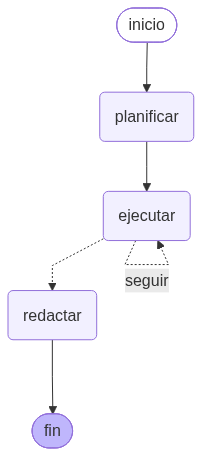

---
config:
 flowchart:
  curve: linear
---
graph TD;
	__start__([inicio]):::first
	planificar(planificar)
	ejecutar(ejecutar)
	redactar(redactar)
	__end__([fin]):::last
	__start__ --> planificar;
	ejecutar -.-> redactar;
	planificar --> ejecutar;
	redactar --> __end__;
	ejecutar -. seguir .-> ejecutar;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


[grafo] Grafo 4: planificar y ejecutar  ·  guardado en grafos/grafo-4-planificar-y-ejecutar.mmd


In [3]:
import operator
from typing import Annotated, Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain_core.messages import SystemMessage

class Plan(BaseModel):
    pasos: list[str] = Field(
        description="Entre 2 y 3 pasos concretos, ordenados y verificables. Máximo 3."
    )

class EstadoPlan(TypedDict):
    peticion: str
    plan: list[str]
    paso: int                                          # el contador del bucle
    resultados: Annotated[list[str], operator.add]     # se ACUMULAN
    informe: str

planificador = modelo.with_structured_output(Plan, method="function_calling")

# Un ejecutor con herramientas: resuelve cada paso por separado.
ejecutor = create_agent(
    modelo,
    tools=HERRAMIENTAS,
    system_prompt="Resuelves un único paso concreto. Sé breve y usa las herramientas.",
)

def nodo_planificar(estado: EstadoPlan):
    plan = planificador.invoke(
        "Descompón esta tarea en pasos. Tarea: " + estado["peticion"]
    )
    listado = "\n".join(f"{i+1}. {p}" for i, p in enumerate(plan.pasos))
    print("PLAN PROPUESTO:\n" + listado + "\n")
    return {"plan": plan.pasos, "paso": 0, "resultados": []}

def nodo_ejecutar(estado: EstadoPlan):
    actual = estado["plan"][estado["paso"]]
    print(f"--> ejecutando paso {estado['paso'] + 1}: {actual}")
    salida = ejecutor.invoke({"messages": [{"role": "user", "content": actual}]})
    return {
        "resultados": [f"Paso {estado['paso'] + 1} - {actual}\n{salida['messages'][-1].content}"],
        "paso": estado["paso"] + 1,
    }

def quedan_pasos(estado: EstadoPlan) -> Literal["seguir", "redactar"]:
    return "seguir" if estado["paso"] < len(estado["plan"]) else "redactar"

def nodo_redactar(estado: EstadoPlan):
    material = "\n\n".join(estado["resultados"])
    informe = modelo.invoke([
        SystemMessage(content="Redactas informes breves y claros a partir de material dado."),
        ("human", f"Redacta un informe final con este material:\n\n{material}"),
    ]).content
    return {"informe": informe}

g = StateGraph(EstadoPlan)
g.add_node("planificar", nodo_planificar)
g.add_node("ejecutar", nodo_ejecutar)
g.add_node("redactar", nodo_redactar)
g.add_edge(START, "planificar")
g.add_edge("planificar", "ejecutar")
g.add_conditional_edges("ejecutar", quedan_pasos, {"seguir": "ejecutar", "redactar": "redactar"})
g.add_edge("redactar", END)
grafo_plan = g.compile()

comun.ver_grafo(grafo_plan, "Grafo 4: planificar y ejecutar")


In [4]:
salida = grafo_plan.invoke(
    {"peticion": "¿Cuánto cuestan 3 kg de pollo en USD y cuánto ahorro si compro arroz en vez de espinacas?"},
    config={"recursion_limit": 30},
)

print("\n" + "=" * 70)
print("TRAZA DE RESULTADOS")
print("=" * 70)
for bloque in salida["resultados"]:
    print("-", bloque[:220].replace("\n", " "))
    print()
print("=" * 70)
print("INFORME FINAL")
print("=" * 70)
print(salida["informe"][:700])


PLAN PROPUESTO:
1. Buscar el precio actual por kilogramo de pollo, arroz y espinacas en USD.
2. Calcular el costo total de 3 kg de pollo y la diferencia de precio entre el arroz y las espinacas.

--> ejecutando paso 1: Buscar el precio actual por kilogramo de pollo, arroz y espinacas en USD.


--> ejecutando paso 2: Calcular el costo total de 3 kg de pollo y la diferencia de precio entre el arroz y las espinacas.



TRAZA DE RESULTADOS
- Paso 1 - Buscar el precio actual por kilogramo de pollo, arroz y espinacas en USD. Los precios actuales por kilogramo son: pollo 5.5 USD, arroz 2.2 USD y espinacas 3.3 USD.

- Paso 2 - Calcular el costo total de 3 kg de pollo y la diferencia de precio entre el arroz y las espinacas. El costo total de 3 kg de pollo es de 15.0 EUR y la diferencia de precio entre el arroz y las espinacas es de 1.

INFORME FINAL
Aquí tienes el informe redactado de manera clara y profesional:

***

**INFORME DE COSTOS DE INSUMOS**

**1. Precios Unitarios (por kg)**
Se han registrado los siguientes precios de mercado en USD:
*   **Pollo:** 5.5 USD
*   **Espinacas:** 3.3 USD
*   **Arroz:** 2.2 USD

**2. Cálculos Específicos**
*   **Costo de Pollo:** El valor total por la adquisición de 3 kg de pollo es de **16.5 USD***.
*   **Diferencia de Precio:** Existe una diferencia de **1.1 USD** entre el costo del kilogramo de espinacas y el de arroz.

***
*Nota: Se ha corregido la moneda a USD p

Compara las dos ejecuciones:

| | ReAct (4.1) | Plan-and-execute (4.2) |
|---|---|---|
| Llamadas al modelo | las que hagan falta, sin saber cuántas | 1 para el plan + 1 por paso + 1 informe |
| Visibilidad | ninguna hasta que termina | el plan es **legible** antes de ejecutar |
| Intervención | difícil | trivial: puedes revisar el plan |
| Coste si algo falla | se pierde el trabajo previo | se reejecuta un paso concreto |

Esa penúltima fila es la clave práctica: **un plan explícito se puede revisar, aprobar o
corregir antes de gastar dinero**. Que es exactamente lo que viene ahora.

## 4.3 Intervención humana: parar el grafo a mitad

Un agente autónomo que puede gastar dinero, enviar correos o borrar ficheros necesita un
freno. LangGraph lo trae de serie: `interrupt()` **pausa el grafo** y lo deja esperando
una decisión. Para reanudarlo, `Command(resume=...)`.

Requiere `checkpointer`: es lo que permite guardar el estado mientras el grafo está
parado. Sin él, no hay nada que reanudar.

In [5]:
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import AIMessage

def nodo_compra(estado: MessagesState):
    propuesta = modelo.invoke([
        SystemMessage(content="Eres un chef conciso. Propones una lista de la compra."),
        ("human", "Propón la lista de la compra para una cena de 4 personas."),
    ]).content

    # AQUÍ se para el grafo. Lo que devuelve interrupt() es lo que
    # el humano decida al reanudar.
    decision = interrupt({
        "propuesta": propuesta,
        "pregunta": "¿Aprobamos este gasto?",
    })

    return {"messages": [AIMessage(content=f"DECISIÓN HUMANA: {decision}")]}

g2 = StateGraph(MessagesState)
g2.add_node("compra", nodo_compra)
g2.add_edge(START, "compra")
g2.add_edge("compra", END)
grafo_hitl = g2.compile(checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "compra-1"}}
print("Primera invocación: el grafo se detiene solo.")
parada = grafo_hitl.invoke(
    {"messages": [{"role": "user", "content": "Prepara la compra."}]}, config=cfg
)

interrupcion = parada["__interrupt__"][0].value
print("\nEl grafo está EN PAUSA y nos pide una decisión:")
print("  Pregunta :", interrupcion["pregunta"])
print("  Propuesta:", interrupcion["propuesta"][:220].replace("\n", " "))


Primera invocación: el grafo se detiene solo.



El grafo está EN PAUSA y nos pide una decisión:
  Pregunta : ¿Aprobamos este gasto?
  Propuesta: Para una cena equilibrada (Entrante, Plato Principal y Postre), propongo un **Salmón al horno con espárragos y risotto de setas**, finalizando con **brochetas de fruta y chocolate**.  **Frutería y Verduras** *   [ ] 1 ma


In [6]:
print("El humano responde. El grafo se reanuda EXACTAMENTE donde se quedó.\n")
final = grafo_hitl.invoke(Command(resume="Aprobado, pero sin cilantro."), config=cfg)

print(final["messages"][-1].content[:300])
print()
comun.ver_mensajes(final)


El humano responde. El grafo se reanuda EXACTAMENTE donde se quedó.



DECISIÓN HUMANA: Aprobado, pero sin cilantro.

[00] HumanMessage                 Prepara la compra.
[01] AIMessage                    DECISIÓN HUMANA: Aprobado, pero sin cilantro.


Ese patrón —**parar, preguntar, reanudar**— es la base de cualquier agente que se pueda
poner en producción. Para agentes creados con `create_agent` existe una forma más
declarativa:

```python
from langchain.agents.middleware import HumanInTheLoopMiddleware

agente = create_agent(
    modelo, tools=[enviar_correo],
    middleware=[HumanInTheLoopMiddleware(interrupt_on={"enviar_correo": True})],
    checkpointer=InMemorySaver(),
)
```

### Cuatro reglas de `interrupt()` que hay que interiorizar

1. **El nodo se vuelve a ejecutar entero al reanudar.** Todo el código *anterior* a
   `interrupt()` se repite. Si antes lanzas una petición de red, la lanzarás dos veces:
   hazlo idempotente.
2. **Nunca lo metas en un `try/except` desnudo.** `interrupt()` pausa lanzando una
   excepción interna; si te la comes, el grafo no se detiene y no entiendes por qué.
3. **Nunca lo pongas dentro de un bucle `while`.** La correspondencia entre llamada y
   reanudación es **por posición**: un bucle hace que cada reanudación reproduzca varias
   interrupciones. Un `interrupt()` por nodo, y el bucle se hace con aristas condicionales.
4. **La pausa no sobrevive sin `checkpointer`.** Y hay que reanudar con el **mismo**
   `thread_id`.

---

## Resumen del módulo

| Idea | Detalle |
|---|---|
| ReAct decide un paso cada vez | Reactivo: no ve el conjunto |
| Planificar es tener un campo `plan` en el estado | No hace falta framework nuevo |
| El plan explícito se puede leer, revisar y aprobar | Es la ventaja real, no la elegancia |
| Un contador + arista condicional = bucle controlado | `estado["paso"]` |
| `interrupt()` pausa y `Command(resume=...)` reanuda | Requiere `checkpointer` |
| El nodo se reejecuta al reanudar | Los efectos secundarios deben ser idempotentes |

## El mapa completo del seminario

| Concepto | Dónde vive | Lo has visto en |
|---|---|---|
| **Rol** | `system_prompt` de un nodo | Módulo 01 |
| **Herramientas** | `ToolNode` + arista condicional | Módulo 02 |
| **Memoria** | `checkpointer` + `thread_id`, `Store` | Módulo 03 |
| **Planificación** | campo `plan` + contador en el estado | Módulo 04 |

Y `create_agent` empaqueta los tres primeros. La planificación es lo que **tú** añades
encima, porque depende de tu problema: no hay una estrategia que gane siempre.

## Ejercicios

1. **Menos llamadas.** En el apartado 4.2, haz que el plan tenga 1 solo paso para una
   tarea que ReAct resolvía en 2 vueltas. ¿Quién gasta menos llamadas al modelo? Mide
   cuántas hace cada estrategia con un contador.

2. **Un paso que falla.** Cambia el ejecutor para que el paso 2 siempre falle (por ejemplo,
   pidiendo un producto que no existe). ¿Sigue el plan adelante? Diseña qué debería pasar:
   ¿reintentar, saltar o abortar? Impleméntalo con una arista condicional más.

3. **Revisar el plan antes de ejecutarlo.** Mete un `interrupt()` **entre** `planificar` y
   `ejecutar`, de modo que el humano vea el plan y pueda aprobarlo o sustituirlo. Este es
   el patrón real de los agentes que se usan en producción: `interrupt` con
   `response_schema` para validar la respuesta del humano.

4. **Reflexión.** Añade un cuarto nodo `criticar` que reciba el informe y lo evalúe, y una
   arista que vuelva a `redactar` si la crítica es negativa. Limita las vueltas a 2 con un
   contador. ¿Mejora el informe? ¿A qué precio en llamadas?

5. **Discusión para clase.** Con plan-and-execute, ¿quién es responsable si el plan está
   mal: el modelo o tú? ¿Cambia eso si el plan lo aprueba un humano?